In [2]:
import pandas as pd
import numpy as np

# 1. Load the CSV files
train_df = pd.read_csv('dataset/KDDTrain+.csv')
test_df = pd.read_csv('dataset/KDDTest+.csv')

# 2. Check if headers are missing (if 'duration' isn't a column, we need to add names)
if 'duration' not in train_df.columns:
    col_names = [
        "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", 
        "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised", 
        "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", 
        "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", 
        "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", 
        "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", 
        "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate", 
        "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", 
        "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", 
        "attack_type", "difficulty_level"
    ]
    # Assign names based on number of columns
    if len(train_df.columns) == len(col_names):
        train_df.columns = col_names
        test_df.columns = col_names
    elif len(train_df.columns) == len(col_names) - 1:
        train_df.columns = col_names[:-1]
        test_df.columns = col_names[:-1]

# 3. Safely drop 'difficulty_level' ONLY if it exists
if 'difficulty_level' in train_df.columns:
    train_df = train_df.drop('difficulty_level', axis=1)
if 'difficulty_level' in test_df.columns:
    test_df = test_df.drop('difficulty_level', axis=1)

# 4. Verify
print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)
display(train_df.head())

Train Shape: (125973, 43)
Test Shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
# 1. Ensure the target column is named 'attack_type'
# If 'attack_type' isn't there, we look for common alternatives
if 'attack_type' not in train_df.columns:
    for col in ['class', 'label', 'attack', 'target']:
        if col in train_df.columns:
            train_df.rename(columns={col: 'attack_type'}, inplace=True)
            test_df.rename(columns={col: 'attack_type'}, inplace=True)
            break

# 2. Map the attacks to categories
def map_attack_category(attack):
    if attack == 'normal':
        return 'Normal'
    elif attack in ['back', 'land', 'neptune', 'pod', 'smurf', 'teardrop', 'apache2', 'mailbomb', 'processtable', 'udpstorm']:
        return 'DoS'
    elif attack in ['ipsweep', 'nmap', 'portsweep', 'satan', 'mscan', 'saint']:
        return 'Probe'
    elif attack in ['ftp_write', 'guess_passwd', 'imap', 'multihop', 'phf', 'spy', 'warezclient', 'warezmaster', 'sendmail', 'named', 'snmpgetattack', 'snmpguess', 'xlock', 'xsnoop', 'worm']:
        return 'R2L'
    elif attack in ['buffer_overflow', 'loadmodule', 'perl', 'rootkit', 'httptunnel', 'ps', 'sqlattack', 'xterm']:
        return 'U2R'
    else:
        return 'Unknown'

# 3. Apply the mapping
train_df['category'] = train_df['attack_type'].apply(map_attack_category)
test_df['category'] = test_df['attack_type'].apply(map_attack_category)

# 4. Print results
print("Unique attacks in Training Set:")
print(train_df['attack_type'].unique())

print("\nUnique attacks in Testing Set:")
print(test_df['attack_type'].unique())

print("\nTraining Set Attack Categories:")
display(train_df['category'].value_counts())

Unique attacks in Training Set:
<StringArray>
[         'normal',         'neptune',     'warezclient',         'ipsweep',
       'portsweep',        'teardrop',            'nmap',           'satan',
           'smurf',             'pod',            'back',    'guess_passwd',
       'ftp_write',        'multihop',         'rootkit', 'buffer_overflow',
            'imap',     'warezmaster',             'phf',            'land',
      'loadmodule',             'spy',            'perl']
Length: 23, dtype: str

Unique attacks in Testing Set:
<StringArray>
[        'neptune',          'normal',           'saint',           'mscan',
    'guess_passwd',           'smurf',         'apache2',           'satan',
 'buffer_overflow',            'back',     'warezmaster',   'snmpgetattack',
    'processtable',             'pod',      'httptunnel',            'nmap',
              'ps',       'snmpguess',         'ipsweep',        'mailbomb',
       'portsweep',        'multihop',           'named',

C:\Users\shrey\AppData\Local\Temp\ipykernel_1232\200513563.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.rename(columns={col: 'attack_type'}, inplace=True)
C:\Users\shrey\AppData\Local\Temp\ipykernel_1232\200513563.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_df.rename(columns={col: 'attack_type'}, inplace=True)


category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

In [4]:
print(train_df.columns)

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'attack_type', 'difficulty', 'category'],
      dtype='str')


In [5]:
# Clean up column names without using inplace=True
if 'label' in train_df.columns:
    train_df = train_df.rename(columns={'label': 'attack_type'})
    test_df = test_df.rename(columns={'label': 'attack_type'})

# Drop the 'difficulty' column safely
train_df = train_df.drop(columns=['difficulty'], errors='ignore')
test_df = test_df.drop(columns=['difficulty'], errors='ignore')

print("Cleaned Columns:", train_df.columns)

Cleaned Columns: Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'attack_type', 'category'],
      dtype='str')


In [6]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
import joblib
import os
import numpy as np

# 1. Encode the SPECIFIC ATTACK TYPE
le = LabelEncoder()
# Fit ONLY on the training data (22 known attacks + normal)
train_df['attack_encoded'] = le.fit_transform(train_df['attack_type'])

# 2. Handle the unseen attacks in the test set gracefully
known_classes = set(le.classes_)
unknown_id = len(le.classes_) # Assign a new numerical ID (e.g., 23) for unknowns

def encode_test_label(label):
    if label in known_classes:
        return le.transform([label])[0]
    else:
        return unknown_id # This catches 'saint' and the other 16 unknown attacks

test_df['attack_encoded'] = test_df['attack_type'].apply(encode_test_label)

# Save the new label encoder for the backend
os.makedirs('../backend/models', exist_ok=True)
joblib.dump(le, '../backend/models/label_encoder.joblib')

print("Classes mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print(f"Mapped unseen test labels to ID: {unknown_id}")

# 3. Separate Features (X) and Target (y)
# FIX: Removed 'category_encoded' from the list
cols_to_drop = ['attack_type', 'category', 'attack_encoded']
X_train = train_df.drop(columns=cols_to_drop)
y_train = train_df['attack_encoded']

X_test = test_df.drop(columns=cols_to_drop)
y_test = test_df['attack_encoded']

# 4. One-Hot Encode Categorical Features
categorical_cols = ['protocol_type', 'service', 'flag']
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols)

# Align columns (ensure test set has the exact same columns as train set)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# 5. Scale Numerical Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

# Save the scaler and feature names for the backend
joblib.dump(scaler, '../backend/models/scaler.joblib')
joblib.dump(X_train_encoded.columns.tolist(), '../backend/models/feature_names.joblib')

print("Preprocessing Complete!")
print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape: {X_test_scaled.shape}")

Classes mapping: {'back': np.int64(0), 'buffer_overflow': np.int64(1), 'ftp_write': np.int64(2), 'guess_passwd': np.int64(3), 'imap': np.int64(4), 'ipsweep': np.int64(5), 'land': np.int64(6), 'loadmodule': np.int64(7), 'multihop': np.int64(8), 'neptune': np.int64(9), 'nmap': np.int64(10), 'normal': np.int64(11), 'perl': np.int64(12), 'phf': np.int64(13), 'pod': np.int64(14), 'portsweep': np.int64(15), 'rootkit': np.int64(16), 'satan': np.int64(17), 'smurf': np.int64(18), 'spy': np.int64(19), 'teardrop': np.int64(20), 'warezclient': np.int64(21), 'warezmaster': np.int64(22)}
Mapped unseen test labels to ID: 23
Preprocessing Complete!
X_train shape: (125973, 122)
X_test shape: (22544, 122)


In [7]:
import xgboost as xgb
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, accuracy_score
import time

# ==========================================
# 1. Train XGBoost (Known Classifier)
# ==========================================
print("Training XGBoost on specific attack types...")
start_time = time.time()

# We use len(le.classes_) because there are now 23 classes (22 attacks + normal)
xgb_clf = xgb.XGBClassifier(
    objective='multi:softprob', 
    num_class=len(le.classes_), 
    max_depth=6, 
    learning_rate=0.1, 
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

xgb_clf.fit(X_train_scaled, y_train)
print(f"XGBoost trained in {time.time() - start_time:.2f} seconds!")

# Save the new XGBoost model
joblib.dump(xgb_clf, '../backend/models/xgb_clf.joblib')
# ==========================================
# 2. Train Isolation Forest (Unknown Detector)
# ==========================================
print("\nTraining Isolation Forest on Normal Traffic only...")
start_time = time.time()

# We only want to train the IF on NORMAL traffic (Label = 1)
# so it learns the baseline behavior of the network
normal_indices = (y_train == 1) 
X_train_normal = X_train_scaled[normal_indices]

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05, # Estimate that ~5% of traffic is anomalous
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(X_train_normal)
print(f"Isolation Forest trained in {time.time() - start_time:.2f} seconds!")

# Save the Isolation Forest model
joblib.dump(iso_forest, '../backend/models/iso_forest.joblib')

Training XGBoost on specific attack types...
XGBoost trained in 72.22 seconds!

Training Isolation Forest on Normal Traffic only...
Isolation Forest trained in 0.52 seconds!


['../backend/models/iso_forest.joblib']

In [8]:
from sklearn.metrics import classification_report

# Predict on the test set
print("Evaluating XGBoost on Test Set...")
y_pred_xgb = xgb_clf.predict(X_test_scaled)

# Get the names of the classes the model was trained on (22 attacks + normal)
trained_classes = list(le.classes_)

# Print the classification report using the specific attack names
# (We use labels=range(len(trained_classes)) because XGBoost only predicts these 23 classes,
# even though the test set contains some unknowns mapped to ID 23).
print(classification_report(
    y_test, 
    y_pred_xgb, 
    labels=range(len(trained_classes)), 
    target_names=trained_classes, 
    zero_division=0
))

Evaluating XGBoost on Test Set...
                 precision    recall  f1-score   support

           back       0.53      0.97      0.68       359
buffer_overflow       0.00      0.00      0.00        20
      ftp_write       0.00      0.00      0.00         3
   guess_passwd       0.00      0.00      0.00      1231
           imap       0.00      0.00      0.00         1
        ipsweep       0.58      0.99      0.73       141
           land       1.00      0.43      0.60         7
     loadmodule       0.00      0.00      0.00         2
       multihop       0.00      0.00      0.00        18
        neptune       0.95      1.00      0.97      4657
           nmap       0.99      1.00      0.99        73
         normal       0.66      0.97      0.79      9711
           perl       1.00      0.50      0.67         2
            phf       1.00      0.50      0.67         2
            pod       0.72      0.93      0.81        41
      portsweep       0.74      0.95      0.83       

In [9]:
import numpy as np

def predict_flow(X_scaled, confidence_tau=0.6, anomaly_tau=0.0):
    """
    Combines XGBoost and Isolation Forest to detect Known and Unknown attacks.
    """
    # 1. Get XGBoost Probabilities
    probs = xgb_clf.predict_proba(X_scaled)
    
    # Get the highest probability (confidence) and the predicted class index
    max_confidence = np.max(probs, axis=1)
    predicted_class_idx = np.argmax(probs, axis=1)
    
    # Map indices back to text labels (DoS, Normal, etc.)
    known_labels = le.inverse_transform(predicted_class_idx)
    
    # 2. Get Isolation Forest Anomaly Scores
    # decision_function returns negative values for anomalies, positive for normal
    anomaly_scores = iso_forest.decision_function(X_scaled)
    
    # 3. Apply the Open-Set Decision Rule
    final_predictions = []
    for i in range(len(X_scaled)):
        # If XGBoost is not confident OR Isolation Forest thinks it's an anomaly
        if max_confidence[i] < confidence_tau or anomaly_scores[i] < anomaly_tau:
            final_predictions.append("UNKNOWN")
        else:
            final_predictions.append(known_labels[i])
            
    return np.array(final_predictions), max_confidence, anomaly_scores

# Let's test it on the 17 unknown attacks!
print("Running Hybrid Inference on Test Set...")
hybrid_preds, confidences, anomalies = predict_flow(X_test_scaled)

# Let's see how many UNKNOWNs we found
unique, counts = np.unique(hybrid_preds, return_counts=True)
print("\nHybrid Predictions Distribution:")
for u, c in zip(unique, counts):
    print(f"{u}: {c}")

Running Hybrid Inference on Test Set...

Hybrid Predictions Distribution:
UNKNOWN: 8566
back: 215
ftp_write: 1
imap: 1
ipsweep: 234
land: 2
neptune: 61
nmap: 73
normal: 12248
phf: 1
pod: 52
portsweep: 5
rootkit: 1
satan: 280
smurf: 639
teardrop: 48
warezclient: 115
warezmaster: 2


In [10]:
# Let's create a dataframe to compare True labels vs Hybrid Predictions
results_df = pd.DataFrame({
    'True_Attack': test_df['attack_type'],
    'True_Category': test_df['category'],
    'Hybrid_Prediction': hybrid_preds
})

# Find the 17 unknown attacks in the test set
unknown_attacks_list = ['apache2', 'mailbomb', 'processtable', 'udpstorm', 'mscan', 'saint', 'sendmail', 'named', 'snmpgetattack', 'snmpguess', 'xlock', 'xsnoop', 'worm', 'httptunnel', 'ps', 'sqlattack', 'xterm']

# Filter for only the unknown attacks
unknowns_only = results_df[results_df['True_Attack'].isin(unknown_attacks_list)]

# How many of these unknown attacks did we successfully flag as "UNKNOWN"?
success_rate = (unknowns_only['Hybrid_Prediction'] == 'UNKNOWN').mean()
print(f"Percentage of Unknown Attacks successfully flagged as UNKNOWN: {success_rate * 100:.2f}%")

# Show a sample of what we caught
display(unknowns_only.head(10))

Percentage of Unknown Attacks successfully flagged as UNKNOWN: 61.12%


,True_Attack,True_Category,Hybrid_Prediction
3,saint,Probe,ipsweep
4,mscan,Probe,UNKNOWN
10,mscan,Probe,normal
21,mscan,Probe,neptune
30,apache2,DoS,UNKNOWN
35,mscan,Probe,UNKNOWN
48,mscan,Probe,UNKNOWN
57,snmpgetattack,R2L,normal
58,processtable,DoS,normal
66,mscan,Probe,UNKNOWN


In [13]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print("Recalculating everything...")

# 1. Load test data again
test_df = pd.read_csv('dataset/KDDTest+.csv')
if 'label' in test_df.columns:
    test_df = test_df.rename(columns={'label': 'attack_type'})

# 2. Re-encode the test labels using the existing 'le' (LabelEncoder)
known_classes = set(le.classes_)
unknown_id = len(le.classes_)

def encode_test_label(label):
    if label in known_classes:
        return le.transform([label])[0]
    else:
        return unknown_id # Maps unknown attacks to ID 23

test_df['attack_encoded'] = test_df['attack_type'].apply(encode_test_label)

# 3. Re-create X_test_scaled
X_test = test_df.drop(columns=['attack_type', 'category', 'category_encoded', 'difficulty_level', 'attack_encoded'], errors='ignore')
X_test_encoded = pd.get_dummies(X_test, columns=['protocol_type', 'service', 'flag'])
X_test_encoded = X_test_encoded.reindex(columns=feature_names, fill_value=0)
X_test_scaled = scaler.transform(X_test_encoded)

# 4. Set y_test
y_test = test_df['attack_encoded']

# 5. Predict and Calculate Metrics (Binary: Normal vs Attack)
y_pred = xgb_clf.predict(X_test_scaled)
normal_idx = np.where(le.classes_ == 'normal')[0][0]

# Convert to binary (0 = Normal, 1 = Attack)
y_test_binary = (y_test != normal_idx).astype(int)
y_pred_binary = (y_pred != normal_idx).astype(int)

cm = confusion_matrix(y_test_binary, y_pred_binary)
tn, fp, fn, tp = cm.ravel()

print("\n--- CONFUSION MATRIX RESULTS ---")
print(f"True Positive (Attacks caught): {tp}")
print(f"False Positive (Normal flagged as attack): {fp}")
print(f"False Negative (Attacks missed): {fn}")
print(f"True Negative (Normal passed): {tn}")

print("\n--- PERFORMANCE METRICS ---")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary) * 100:.2f}%")
print(f"Precision: {precision_score(y_test_binary, y_pred_binary) * 100:.2f}%")
print(f"Recall: {recall_score(y_test_binary, y_pred_binary) * 100:.2f}%")
print(f"F1-Score: {f1_score(y_test_binary, y_pred_binary) * 100:.2f}%")

Recalculating everything...

--- CONFUSION MATRIX RESULTS ---
True Positive (Attacks caught): 7973
False Positive (Normal flagged as attack): 267
False Negative (Attacks missed): 4860
True Negative (Normal passed): 9444

--- PERFORMANCE METRICS ---
Accuracy: 77.26%
Precision: 96.76%
Recall: 62.13%
F1-Score: 75.67%


c:\Users\shrey\OneDrive\Desktop\AENIDS\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Explaining why Flow #0 is an UNKNOWN anomaly:
True Attack: neptune
XGBoost guessed: DoS


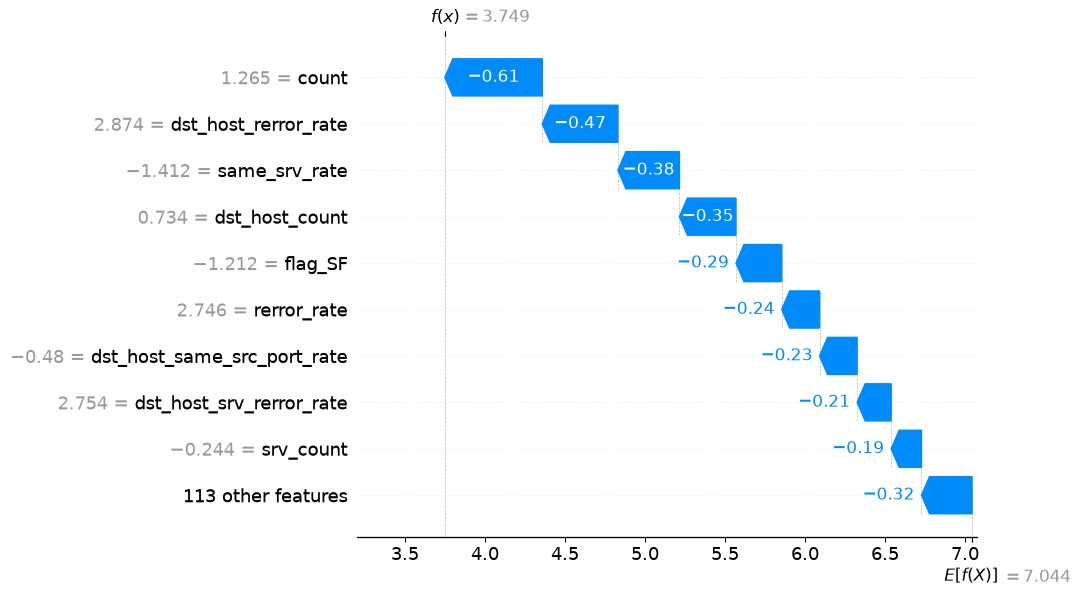

In [14]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# 1. Create the SHAP explainer for the Isolation Forest
if_explainer = shap.TreeExplainer(iso_forest)

# 2. Find the first unknown flow
unknown_indices = np.where(hybrid_preds == 'UNKNOWN')[0]
sample_idx = unknown_indices[0]

# 3. Reshape the data to 2D
sample_flow = X_test_scaled[sample_idx:sample_idx+1]

# 4. Calculate SHAP values
if_shap_values = if_explainer.shap_values(sample_flow)

print(f"Explaining why Flow #{sample_idx} is an UNKNOWN anomaly:")
print(f"True Attack: {results_df.iloc[sample_idx]['True_Attack']}")
print(f"XGBoost guessed: {results_df.iloc[sample_idx]['True_Category']}")

# 5. Plot the SHAP Waterfall
# FIX: We access [0] on the expected_value to get the float number instead of an array
shap.plots.waterfall(
    shap.Explanation(
        values=if_shap_values[0], 
        base_values=if_explainer.expected_value[0] if isinstance(if_explainer.expected_value, (list, np.ndarray)) else if_explainer.expected_value, 
        data=sample_flow[0], 
        feature_names=feature_names
    )
)

In [15]:
from sklearn.cluster import KMeans
import json

# 1. Isolate all unknown flows
X_unknowns = X_test_scaled[hybrid_preds == 'UNKNOWN']
unknown_meta = results_df[hybrid_preds == 'UNKNOWN'].copy()

# 2. Cluster them into 3 provisional families
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_unknowns)

# Assign provisional names
unknown_meta['Provisional_Class'] = [f"Unknown_Cluster_{c}" for c in cluster_labels]

# 3. Generate the JSON Payload for the Frontend
def generate_alert_payload(flow_idx_in_unknowns):
    global_idx = unknown_meta.index[flow_idx_in_unknowns] # Get original row index
    
    # Get SHAP values for this flow
    flow_2d = X_test_scaled[global_idx:global_idx+1]
    flow_shap = if_explainer.shap_values(flow_2d)[0]
    
    # Sort features by absolute SHAP contribution
    top_features_idx = np.argsort(np.abs(flow_shap))[-4:][::-1] # Get top 4 features
    
    explanation = []
    for idx in top_features_idx:
        explanation.append({
            "feature": feature_names[idx],
            "value": round(float(flow_2d[0][idx]), 4),
            "impact": round(float(flow_shap[idx]), 4)
        })
        
    payload = {
        "alert_id": f"ALT-{global_idx}",
        "status": "UNKNOWN_ANOMALY",
        "provisional_classification": unknown_meta.iloc[flow_idx_in_unknowns]['Provisional_Class'],
        "xgb_guess": unknown_meta.iloc[flow_idx_in_unknowns]['True_Category'], 
        "shap_explanation": explanation,
        "human_review_required": True,
        "review_options": ["New DoS", "New Probe", "New R2L", "New U2R", "False Positive"]
    }
    return payload

# Generate a sample payload for the first UNKNOWN flow
sample_alert = generate_alert_payload(0)

print("=== JSON Payload sent to React Frontend ===")
print(json.dumps(sample_alert, indent=4))

=== JSON Payload sent to React Frontend ===
{
    "alert_id": "ALT-0",
    "status": "UNKNOWN_ANOMALY",
    "provisional_classification": "Unknown_Cluster_0",
    "xgb_guess": "DoS",
    "shap_explanation": [
        {
            "feature": "count",
            "value": 1.2653,
            "impact": -0.6086
        },
        {
            "feature": "dst_host_rerror_rate",
            "value": 2.8744,
            "impact": -0.4727
        },
        {
            "feature": "same_srv_rate",
            "value": -1.4124,
            "impact": -0.3845
        },
        {
            "feature": "dst_host_count",
            "value": 0.7343,
            "impact": -0.3533
        }
    ],
    "human_review_required": true,
    "review_options": [
        "New DoS",
        "New Probe",
        "New R2L",
        "New U2R",
        "False Positive"
    ]
}


In [16]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Predict on the test set using your XGBoost model
y_pred = xgb_clf.predict(X_test_scaled)

# Calculate Confusion Matrix
# Note: Because we mapped unknown attacks to ID 23, we need to filter them out for a strict 
# 5-class (or normal vs attack) confusion matrix, or just look at binary Normal vs Attack.
# Let's do a Binary Confusion Matrix (Normal vs Attack) for simplicity in the UI.
# Assuming class 'normal' is at the index of 'normal' in le.classes_
normal_idx = np.where(le.classes_ == 'normal')[0][0]

# Convert to binary (0 = Normal, 1 = Attack)
y_test_binary = (y_test != normal_idx).astype(int)
y_pred_binary = (y_pred != normal_idx).astype(int)

cm = confusion_matrix(y_test_binary, y_pred_binary)
tn, fp, fn, tp = cm.ravel()

print(f"True Positive (Attacks caught): {tp}")
print(f"False Positive (Normal flagged as attack): {fp}")
print(f"False Negative (Attacks missed): {fn}")
print(f"True Negative (Normal passed): {tn}")

print(f"\nAccuracy: {accuracy_score(y_test_binary, y_pred_binary):.2f}")
print(f"Precision: {precision_score(y_test_binary, y_pred_binary):.2f}")
print(f"Recall: {recall_score(y_test_binary, y_pred_binary):.2f}")
print(f"F1-Score: {f1_score(y_test_binary, y_pred_binary):.2f}")

True Positive (Attacks caught): 7973
False Positive (Normal flagged as attack): 267
False Negative (Attacks missed): 4860
True Negative (Normal passed): 9444

Accuracy: 0.77
Precision: 0.97
Recall: 0.62
F1-Score: 0.76
